# **Mission 3 - Exploratory Data Analysis (EDA) with the Sales Dataset using Pandas and d Matplotlib/Seaborn**

### **Objective:**

The goal of this assignment is to help you apply your knowledge of Python for basic operations, Pandas for data manipulation, and Matplotlib/Seaborn for visualizations. You'll be working with a real-world dataset, and your tasks will include loading the data, performing EDA, and visualising the results.

###  **Dataset**

The dataset represents transaction data from a retail business, specifically sales data for products sold in various stores. It contains multiple tables that provide insights into sales, invoices, and products. Let’s break down the tables and what they represent:

#### Sales Table:

InvoiceNo: The unique identifier for each invoice (or transaction).

StockCode: A unique identifier for each product.

Quantity: The number of units sold in each transaction.

UnitPrice: The price per unit of the product.

InvoiceDate: The date when the transaction occurred.

#### Invoice Table:

InvoiceNo: The same unique identifier for each invoice, linking the sales data with the invoice details.

Country: The country where the sale was made.

#### Product Table:

StockCode: A unique identifier for each product.

Description: The name or description of the product.

Product_Category: The category the product belongs to (e.g., "Gift", "Sign", "Mug").



You will need to merge them and perform the following tasks step by step.


### Task 1: Load the Excel File
#### Objective: Import the data from the provided Excel file into Python using Pandas.

Instructions:

1. Upload the provided excel file into Fabric environment
2. Read each sheet of the excel file as a separate dataframe. 
3. Name the dataframe for sales as df_sales, the dataframe for invoice as df_invoice and the dataframe for product as df_product
4. Display the first few rows of each DataFrame to understand its structure.



The excel file loaded into fabric and the sheets were imported into separate Data Frames for analysis.

In [5]:
import pandas as pd

excel_file = pd.ExcelFile("/lakehouse/default/Files/Online Sales Retailer 1.xlsx")

print(excel_file.sheet_names)

['Sales', 'Invoice', 'Product', 'December_Sales']


In [6]:
import os

for root, dirs, files in os.walk('.'):
      for file in files:
        if file.endswith('.xlsx'):
            print(os.path.join(root,
            file))

In [7]:
import pandas as pd

df = pd.read_excel("/lakehouse/default/Files/Online Sales Retailer 1.xlsx")

df.head()

,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate
0,536365,71053,6,3.39,2015-01-01
1,536365,22752,2,7.65,2015-01-01
2,536365,84406,8,2.75,2015-01-01
3,536366,84029,6,3.39,2015-01-01
4,536366,21730,6,4.25,2015-01-01


### Task 2: Basic Python and Pandas Operations
#### Objective: Perform basic Python and Pandas operations to manipulate the data.

<mark>Instructions:</mark>

1. Create the Sales Column (Quantity * Unit Price) 

2. Check for missing values in the Sales DataFrame.

3. Replace any NaN values in the Sales and UnitPrice columns with 0.

4. Calculate basic descriptive statistics for the Quantity and UnitPrice columns (mean, median, mode, standard deviation).

A sales column was created, missing values were checked, and descriptive statistics were calculated to understand the data.

In [8]:
df_sales=df

In [9]:
df_sales = pd.read_excel(excel_file,sheet_name='Sales')
df_invoice = pd.read_excel(excel_file,sheet_name='Invoice')
df_product = pd.read_excel(excel_file,sheet_name='Product')


In [10]:
print(df_sales.columns)

Index(['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'InvoiceDate'], dtype='object')


In [11]:
df_sales["sales"] = df_sales["Quantity"]*df_sales["UnitPrice"]

df_sales.head


<bound method NDFrame.head of        InvoiceNo  StockCode  Quantity  UnitPrice InvoiceDate  sales
0         536365      71053         6       3.39  2015-01-01  20.34
1         536365      22752         2       7.65  2015-01-01  15.30
2         536365      84406         8       2.75  2015-01-01  22.00
3         536366      84029         6       3.39  2015-01-01  20.34
4         536366      21730         6       4.25  2015-01-01  25.50
...          ...        ...       ...        ...         ...    ...
83272     564122      21210        12       1.45  2018-12-31  17.40
83273     564122      22773        12       1.25  2018-12-31  15.00
83274     564123      21080        12       0.85  2018-12-31  10.20
83275     564123      21673        12       1.25  2018-12-31  15.00
83276     564123      85174         2       4.95  2018-12-31   9.90

[83277 rows x 6 columns]>

In [12]:
df_sales.isnull().sum(
    
)

InvoiceNo      0
StockCode      0
Quantity       0
UnitPrice      0
InvoiceDate    0
sales          0
dtype: int64

In [13]:
df_sales[['Quantity','UnitPrice']].describe()


,Quantity,UnitPrice
count,83277.000000,83277.000000
mean,13.610961,3.083503
std,261.577565,5.177653
min,1.000000,0.000000
25%,2.000000,1.250000
50%,6.000000,1.950000
75%,12.000000,3.750000
max,74215.000000,295.000000


## Task 4: Exploratory Data Analysis (EDA)
### Objective: Conduct EDA by analysing the data, identifying patterns, trends, and outliers.

Instructions:

Use describe() to calculate summary statistics for numeric columns.

Perform basic filtering, such as filtering out sales with Quantity equal to 0.

Check for outliers in the Sales column by using a scatter plot.

summary statics,data filtering, and scatter plots were used to explore patterns and identify possible outliers.

In [14]:
df_sales.describe()


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,sales
count,83277.000000,83277.000000,83277.000000,83277.000000,83277,83277.000000
mean,550244.000000,32948.774860,13.610961,3.083503,2016-12-31 00:00:00,23.121043
min,536365.000000,10002.000000,1.000000,0.000000,2015-01-01 00:00:00,0.000000
25%,543304.000000,21843.000000,2.000000,1.250000,2016-01-01 00:00:00,5.000000
50%,550244.000000,22470.000000,6.000000,1.950000,2016-12-31 00:00:00,12.500000
75%,557184.000000,22941.000000,12.000000,3.750000,2017-12-31 00:00:00,19.500000
max,564123.000000,90214.000000,74215.000000,295.000000,2018-12-31 00:00:00,77183.600000
std,8013.381169,22938.831323,261.577565,5.177653,NaN,278.041319


In [15]:
df_filtered = df_sales[df_sales['Quantity'] !=0]

df_filtered.head()


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,sales
0,536365,71053,6,3.39,2015-01-01,20.34
1,536365,22752,2,7.65,2015-01-01,15.30
2,536365,84406,8,2.75,2015-01-01,22.00
3,536366,84029,6,3.39,2015-01-01,20.34
4,536366,21730,6,4.25,2015-01-01,25.50


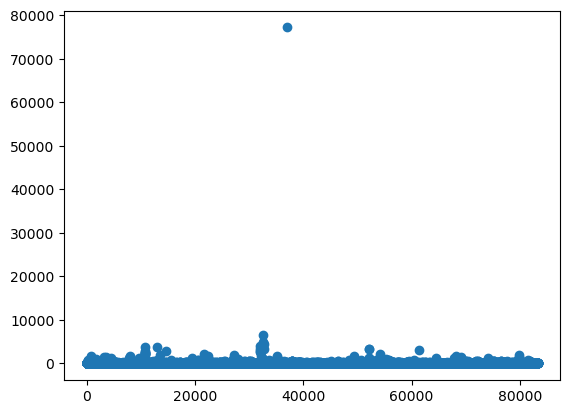

In [16]:
import matplotlib.pyplot as plt

plt.scatter(df_sales.index,df_sales['sales'])
plt.show()


## Task 5: Data Visualisation – Scatter Plot, Histogram, and Line Chart
### Objective: Create scatter plots, histograms, and line charts to better understand the data.

Instructions:

Use a scatter plot to examine the relationship between Quantity and Sales.

Use a histogram to visualise the distribution of the Sales column.

Use a line chart to show the trend of Sales over time.

Write 1–2 sentences explaining the insights from each visualisation.

scatter plots, histograms, and line charts were created to visualize relationships,distributions, and trends in the data.

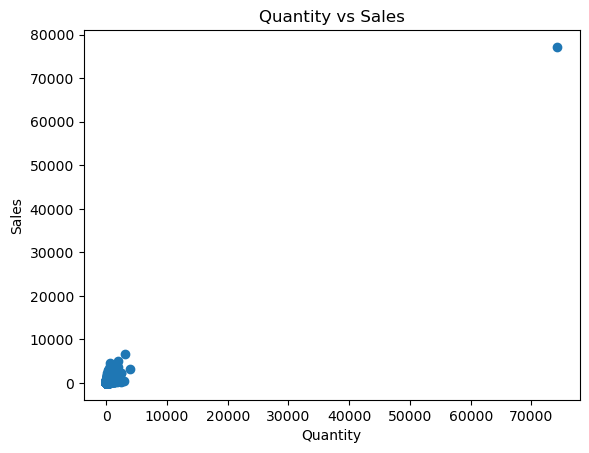

In [17]:
import matplotlib.pyplot as plt

plt.scatter(df_sales['Quantity'],df_sales['sales'])
plt.title('Quantity vs Sales')
plt.xlabel('Quantity')
plt.ylabel('Sales')
plt.show()


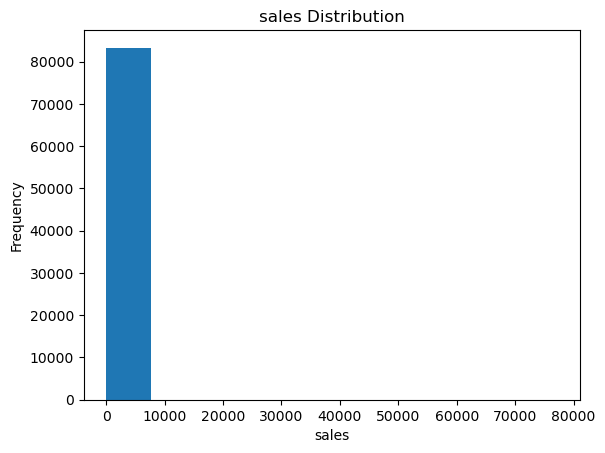

In [18]:
plt.hist(df_sales['sales'])
plt.title('sales Distribution')
plt.xlabel('sales')
plt.ylabel('Frequency')
plt.show()


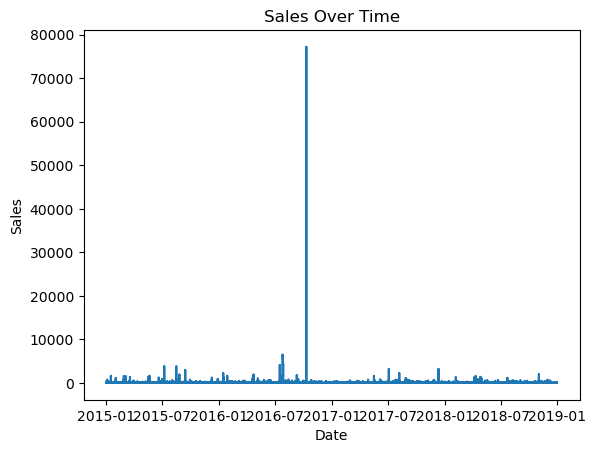

In [19]:
plt.plot(df_sales['InvoiceDate'],df_sales['sales'])
plt.title('Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()


## Task 6: Correlation and Data Insights
### Objective: Identify the relationship between different numerical columns in the dataset.

Instructions:

Calculate the correlation between Quantity and Sales.

Visualise the correlation matrix using a heatmap.

Write 1–2 sentences explaining the insights from the visualisation.

In [20]:
df_sales[['Quantity', 'sales']].corr()


,Quantity,sales
Quantity,1.000000,0.978609
sales,0.978609,1.000000


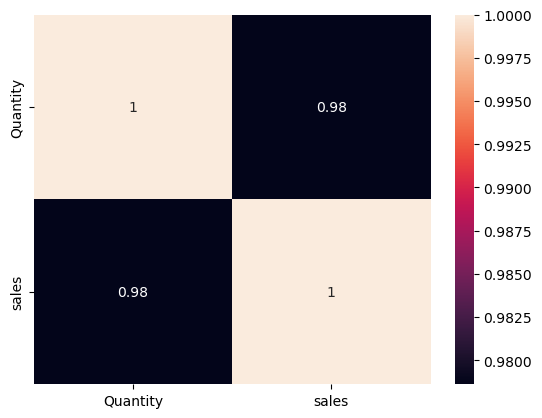

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(df_sales[['Quantity', 'sales']].corr(), annot=True)
plt.show()


There is a positive correlation between Quantity and sales. Higher Quantities generally leads to higher sales.

## Task 7: Grouping and Aggregating
### Objective: Perform grouping and aggregation operations to summarise the data.

Instructions:

GroupBy operation: Group by Product_Category and calculate the total Sales per category.

Create a Pivot Table to show Sales by Country and Product_Category.

sales were grouped category and aggregated to identify the total sales for each category using group-by and pivot table operations.

In [22]:
print(df_product.columns)


Index(['StockCode', 'Description', 'Product_Category'], dtype='object')


In [23]:
df_merged = pd.merge(df_sales,df_product, on='StockCode')


In [25]:
print(df_merged.columns)


Index(['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'InvoiceDate',
       'sales', 'Description', 'Product_Category'],
      dtype='object')


In [26]:
df_merged.groupby('Product_Category')['sales'].sum()


Product_Category
APRON            3858.13
BACKPACK           97.30
BADGES           2415.15
BAG             45694.01
BALLOONS          297.12
                  ...   
WINDMILL          201.64
WOOD LETTERS     3126.40
WOODEN            311.75
WRAP            24542.26
WRITING          1448.80
Name: sales, Length: 170, dtype: float64

In [28]:
pd.pivot_table(
    df_merged,
    values='sales',
    index='Product_Category',
    aggfunc='sum'
)


,sales
Product_Category,
APRON,3858.13
BACKPACK,97.30
BADGES,2415.15
BAG,45694.01
BALLOONS,297.12
...,...
WINDMILL,201.64
WOOD LETTERS,3126.40
WOODEN,311.75


## Submission Guidelines:
Submit the Python notebook with all the tasks and visualisations.

Ensure that each task is clearly explained and that all steps are followed.

Include markdown explanations where necessary to explain your thought process.

Good work